In [ ]:
# Task 33: Simple Linear Regression

## Objective
Build a Simple Linear Regression model using one numerical
input feature to predict a numerical target.

## Deliverables
- Prepared salary and experience dataset
- Trained Linear Regression model
- Predictions on test data
- Model evaluation
- Regression line visualization
- Explanation of the model

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Salary vs Experience Dataset

data = {
    "years_experience": [
        1, 2, 3, 4, 5,
        6, 7, 8, 9, 10,
        11, 12, 13, 14, 15,
        16, 17, 18, 19, 20
    ],

    "annual_salary_inr": [
        300000, 340000, 390000, 420000, 470000,
        500000, 550000, 580000, 630000, 660000,
        710000, 740000, 790000, 820000, 870000,
        900000, 950000, 980000, 1030000, 1060000
    ]
}

# Create DataFrame
df = pd.DataFrame(data)

print("Salary dataset created successfully!")

print("Total employee records:", len(df))

display(df)

Salary dataset created successfully!
Total employee records: 20


,years_experience,annual_salary_inr
0,1,300000
1,2,340000
2,3,390000
3,4,420000
4,5,470000
5,6,500000
6,7,550000
7,8,580000
8,9,630000
9,10,660000


In [3]:
# Save original dataset
df.to_csv(
    "salary_experience_dataset.csv",
    index=False
)

# Load CSV using Pandas
df = pd.read_csv(
    "salary_experience_dataset.csv"
)

print("Dataset loaded successfully!")

display(df.head(10))

Dataset loaded successfully!


,years_experience,annual_salary_inr
0,1,300000
1,2,340000
2,3,390000
3,4,420000
4,5,470000
5,6,500000
6,7,550000
7,8,580000
8,9,630000
9,10,660000


In [4]:
print("DATASET DIMENSIONS")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

DATASET DIMENSIONS
Rows: 20
Columns: 2

Column names:
['years_experience', 'annual_salary_inr']

Data types:
years_experience     int64
annual_salary_inr    int64
dtype: object

First five records:


,years_experience,annual_salary_inr
0,1,300000
1,2,340000
2,3,390000
3,4,420000
4,5,470000



Last five records:


,years_experience,annual_salary_inr
15,16,900000
16,17,950000
17,18,980000
18,19,1030000
19,20,1060000


In [5]:
print("SALARY DATASET STATISTICAL SUMMARY")

display(df.describe())

SALARY DATASET STATISTICAL SUMMARY


,years_experience,annual_salary_inr
count,20.00000,2.000000e+01
mean,10.50000,6.845000e+05
std,5.91608,2.370981e+05
min,1.00000,3.000000e+05
25%,5.75000,4.925000e+05
50%,10.50000,6.850000e+05
75%,15.25000,8.775000e+05
max,20.00000,1.060000e+06


In [6]:
# Independent variable (input feature)
X = df[["years_experience"]]

# Dependent variable (target)
y = df["annual_salary_inr"]

print("INPUT FEATURE (X)")
display(X.head())

print("\nTARGET VARIABLE (y)")
display(y.head())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

INPUT FEATURE (X)


,years_experience
0,1
1,2
2,3
3,4
4,5



TARGET VARIABLE (y)


,annual_salary_inr
0,300000
1,340000
2,390000
3,420000
4,470000



X shape: (20, 1)
y shape: (20,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("=" * 55)
print("             TRAIN-TEST SPLIT")
print("=" * 55)

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining data:")
display(X_train.head())

print("\nTesting data:")
display(X_test.head())

             TRAIN-TEST SPLIT

Training feature shape: (16, 1)
Testing feature shape: (4, 1)

Training target shape: (16,)
Testing target shape: (4,)

Training records: 16
Testing records: 4

Training data:


,years_experience
8,9
5,6
11,12
3,4
18,19



Testing data:


,years_experience
0,1
17,18
15,16
1,2


In [8]:
model = LinearRegression()

print("Linear Regression model initialized successfully!")

Linear Regression model initialized successfully!


In [9]:
# Train the model using training data
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [10]:
# Get the model coefficient
coefficient = model.coef_[0]

# Get the model intercept
intercept = model.intercept_

print("=" * 55)
print("           LINEAR REGRESSION PARAMETERS")
print("=" * 55)

print(f"\nCoefficient (Slope): {coefficient:.2f}")

print(f"Intercept: {intercept:.2f}")

print("\nRegression Equation:")

print(
    f"Salary = {intercept:.2f} + "
    f"({coefficient:.2f} * Experience)"
)

           LINEAR REGRESSION PARAMETERS

Coefficient (Slope): 40040.72
Intercept: 265184.74

Regression Equation:
Salary = 265184.74 + (40040.72 * Experience)


In [11]:
# Predict salary using testing features
y_pred = model.predict(X_test)

print("SALARY PREDICTIONS")

for actual, predicted in zip(y_test, y_pred):

    print(
        f"Actual Salary: ₹{actual:,.2f} | "
        f"Predicted Salary: ₹{predicted:,.2f}"
    )

SALARY PREDICTIONS
Actual Salary: ₹300,000.00 | Predicted Salary: ₹305,225.46
Actual Salary: ₹980,000.00 | Predicted Salary: ₹985,917.66
Actual Salary: ₹900,000.00 | Predicted Salary: ₹905,836.22
Actual Salary: ₹340,000.00 | Predicted Salary: ₹345,266.17


In [12]:
# Calculate regression evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("=" * 55)
print("           MODEL EVALUATION RESULTS")
print("=" * 55)

print(f"\nMean Absolute Error (MAE): ₹{mae:,.2f}")

print(f"Mean Squared Error (MSE): {mse:,.2f}")

print(f"Root Mean Squared Error (RMSE): ₹{rmse:,.2f}")

print(f"R-squared (R2): {r2:.4f}")

           MODEL EVALUATION RESULTS

Mean Absolute Error (MAE): ₹5,561.38
Mean Squared Error (MSE): 31,029,545.81
Root Mean Squared Error (RMSE): ₹5,570.42
R-squared (R2): 0.9997


In [13]:
predictions_df = pd.DataFrame({
    "years_experience": X_test["years_experience"].values,

    "actual_salary_inr": y_test.values,

    "predicted_salary_inr": np.round(y_pred, 2)
})

predictions_df["absolute_error_inr"] = (
    predictions_df["actual_salary_inr"] -
    predictions_df["predicted_salary_inr"]
).abs().round(2)

predictions_df = predictions_df.sort_values(
    by="years_experience"
).reset_index(drop=True)

print("ACTUAL VS PREDICTED SALARY")

display(predictions_df)

ACTUAL VS PREDICTED SALARY


,years_experience,actual_salary_inr,predicted_salary_inr,absolute_error_inr
0,1,300000,305225.46,5225.46
1,2,340000,345266.17,5266.17
2,16,900000,905836.22,5836.22
3,18,980000,985917.66,5917.66


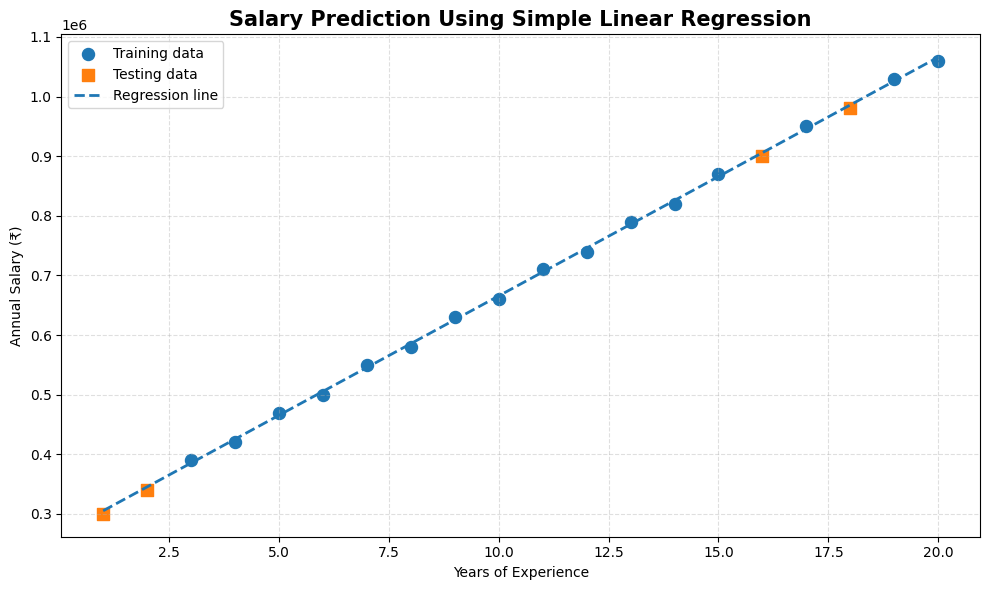

In [14]:
# Create charts folder
Path("charts").mkdir(exist_ok=True)

# Generate experience values for the regression line
experience_line = pd.DataFrame({
    "years_experience": np.linspace(
        df["years_experience"].min(),
        df["years_experience"].max(),
        100
    )
})

# Predict salary for the regression line
salary_line = model.predict(experience_line)

# Create chart
plt.figure(figsize=(10, 6))

# Plot training observations
plt.scatter(
    X_train["years_experience"],
    y_train,
    s=75,
    label="Training data"
)

# Plot testing observations
plt.scatter(
    X_test["years_experience"],
    y_test,
    s=85,
    marker="s",
    label="Testing data"
)

# Plot regression line
plt.plot(
    experience_line["years_experience"],
    salary_line,
    linestyle="--",
    linewidth=2,
    label="Regression line"
)

plt.title(
    "Salary Prediction Using Simple Linear Regression",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Years of Experience")
plt.ylabel("Annual Salary (₹)")

plt.grid(
    True,
    linestyle="--",
    alpha=0.4
)

plt.legend()
plt.tight_layout()

# Save chart
plt.savefig(
    "charts/salary_regression_line.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
# New employee with 12 years of experience

new_employee = pd.DataFrame({
    "years_experience": [12]
})

# Predict salary
new_salary = model.predict(new_employee)

print("NEW EMPLOYEE SALARY PREDICTION")

print("Years of Experience: 12")

print(
    f"Predicted Annual Salary: ₹{new_salary[0]:,.2f}"
)

NEW EMPLOYEE SALARY PREDICTION
Years of Experience: 12
Predicted Annual Salary: ₹745,673.35


In [16]:
model_summary = pd.DataFrame({
    "Metric": [
        "Total Dataset Records",
        "Training Records",
        "Testing Records",
        "Input Feature",
        "Target Variable",
        "Regression Coefficient",
        "Model Intercept",
        "Mean Absolute Error",
        "Mean Squared Error",
        "Root Mean Squared Error",
        "R-Squared Score"
    ],

    "Value": [
        len(df),
        len(X_train),
        len(X_test),
        "years_experience",
        "annual_salary_inr",
        round(coefficient, 2),
        round(intercept, 2),
        round(mae, 2),
        round(mse, 2),
        round(rmse, 2),
        round(r2, 4)
    ]
})

print("FINAL MODEL SUMMARY")

display(model_summary)

FINAL MODEL SUMMARY


,Metric,Value
0,Total Dataset Records,20
1,Training Records,16
2,Testing Records,4
3,Input Feature,years_experience
4,Target Variable,annual_salary_inr
5,Regression Coefficient,40040.72
6,Model Intercept,265184.74
7,Mean Absolute Error,5561.38
8,Mean Squared Error,31029545.81
9,Root Mean Squared Error,5570.42


In [17]:
# Save original dataset
df.to_csv(
    "salary_experience_dataset.csv",
    index=False
)

# Save prediction results
predictions_df.to_csv(
    "regression_predictions.csv",
    index=False
)

# Save model evaluation summary
model_summary.to_csv(
    "model_summary.csv",
    index=False
)

print("All project CSV files exported successfully!")

All project CSV files exported successfully!


In [18]:
from google.colab import files

files.download("salary_experience_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
files.download("regression_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
files.download("model_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
files.download("charts/salary_regression_line.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>